# Cryptocurrency Price Forecasting

## Exploratory Data Analysis (EDA)

### Algorithms
- Prophet
- HistGradientBoosting

### Objective

To analyze historical Bitcoin price data and understand its structure, quality, trends, price movements, trading volume, feature relationships, and potential outliers before applying machine learning and time-series forecasting models.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
data_path = Path("../data/engineered_data.csv")

df = pd.read_csv(data_path)

print("Shape:", df.shape)

Shape: (3011, 18)


Display the first few rows

In [4]:
df.head()

,Date,Open,High,Low,Close,Volume,Return,SMA_7,SMA_14,Volatility_7,RSI_14,MACD,MACD_Signal,Lag_1,Lag_2,Lag_3,Volume_Change,Target
0,2013-12-27,763.280029,777.510010,713.599976,735.070007,46862700.0,-0.035316,677.298567,694.134282,0.059191,49.915908,-25.829491,-20.818665,761.979980,682.210022,665.580017,inf,727.830017
1,2013-12-28,737.979980,747.059998,705.349976,727.830017,32505800.0,-0.009849,694.751430,683.793570,0.056262,49.465334,-22.581305,-21.171193,735.070007,761.979980,682.210022,-0.306361,745.049988
2,2013-12-29,728.049988,748.609985,714.440002,745.049988,19011300.0,0.023659,713.018572,674.431427,0.056167,50.607340,-18.405421,-20.618038,727.830017,735.070007,761.979980,-0.415141,756.130005
3,2013-12-30,741.349976,766.599976,740.239990,756.130005,20707700.0,0.014872,724.835720,678.014287,0.048943,51.368868,-14.040092,-19.302449,745.049988,727.830017,735.070007,0.089231,754.010010
4,2013-12-31,760.320007,760.580017,738.169983,754.010010,20897300.0,-0.002804,737.468576,683.149288,0.048171,51.206191,-10.629078,-17.567775,756.130005,745.049988,727.830017,0.009156,771.400024


Check the last few rows

In [5]:
df.tail()

,Date,Open,High,Low,Close,Volume,Return,SMA_7,SMA_14,Volatility_7,RSI_14,MACD,MACD_Signal,Lag_1,Lag_2,Lag_3,Volume_Change,Target
3006,2022-09-19,19418.571422,19639.479733,18390.318710,19544.129250,4.017700e+10,0.006417,20457.202912,21513.710661,0.070070,38.823776,-1414.319721,-1554.998357,19419.506191,22370.448650,21769.256340,0.285467,18802.097976
3007,2022-09-25,18936.311515,19134.733194,18696.468304,18802.097976,2.335997e+10,-0.037967,20243.503389,21201.296885,0.069737,36.762354,-1481.576754,-1540.314037,19544.129250,19419.506191,22370.448650,-0.418574,19044.107272
3008,2022-10-02,19311.848708,19370.309281,18970.620583,19044.107272,2.076596e+10,0.012871,20108.845308,20860.912610,0.070106,37.920104,-1498.081360,-1531.867501,18802.097976,19544.129250,19419.506191,-0.111045,19446.426194
3009,2022-10-09,19417.479411,19542.538654,19349.258953,19446.426194,1.683726e+10,0.021126,20056.567410,20512.847773,0.070725,39.890286,-1461.846350,-1517.863271,19044.107272,18802.097976,19544.129250,-0.189189,19268.092801
3010,2022-10-16,19068.913560,19389.603520,19068.913560,19268.092801,1.798892e+10,-0.009170,19699.258333,20165.070657,0.055650,39.294981,-1431.023905,-1500.495398,19446.426194,19044.107272,18802.097976,0.068399,19567.007398


Check dataset information

In [6]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3011 entries, 0 to 3010
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           3011 non-null   str    
 1   Open           3011 non-null   float64
 2   High           3011 non-null   float64
 3   Low            3011 non-null   float64
 4   Close          3011 non-null   float64
 5   Volume         3011 non-null   float64
 6   Return         3011 non-null   float64
 7   SMA_7          3011 non-null   float64
 8   SMA_14         3011 non-null   float64
 9   Volatility_7   3011 non-null   float64
 10  RSI_14         3011 non-null   float64
 11  MACD           3011 non-null   float64
 12  MACD_Signal    3011 non-null   float64
 13  Lag_1          3011 non-null   float64
 14  Lag_2          3011 non-null   float64
 15  Lag_3          3011 non-null   float64
 16  Volume_Change  3011 non-null   float64
 17  Target         3011 non-null   float64
dtypes: float64(17), str

Check column names

In [8]:
print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Return', 'SMA_7', 'SMA_14', 'Volatility_7', 'RSI_14', 'MACD', 'MACD_Signal', 'Lag_1', 'Lag_2', 'Lag_3', 'Volume_Change', 'Target']


In [9]:
# Statistical summary of numerical columns

df.describe()

c:\Users\Abhijith Varun\Crypto_Forecasting\.venv312\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Open,High,Low,Close,Volume,Return,SMA_7,SMA_14,Volatility_7,RSI_14,MACD,MACD_Signal,Lag_1,Lag_2,Lag_3,Volume_Change,Target
count,3011.000000,3011.000000,3011.000000,3011.000000,3.011000e+03,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000,3011.000000
mean,10418.708869,10692.696833,10118.692481,10431.473484,1.340625e+10,0.001885,10412.997151,10390.215615,0.033922,52.744595,50.876674,52.844033,10425.327316,10419.095428,10412.991633,inf,10437.727864
std,15391.066163,15794.217357,14930.677270,15399.569087,1.926822e+10,0.040063,15376.816091,15350.919242,0.021413,14.259883,989.345520,941.590730,15399.734120,15399.878998,15400.101503,NaN,15399.453882
min,176.897003,211.731003,171.509995,178.102997,2.857830e+06,-0.371695,204.545569,222.873070,0.001998,9.920237,-5084.110991,-4547.801921,178.102997,178.102997,178.102997,-0.869188,178.102997
25%,576.005981,583.275024,565.700989,575.998993,5.564385e+07,-0.013782,578.732574,581.183435,0.018407,42.578237,-41.050013,-38.102807,575.998993,575.998993,575.998993,-0.151636,575.998993
50%,4465.540000,4626.520020,4343.980000,4565.299805,4.139365e+09,0.001542,4463.474346,4443.858573,0.029356,51.575181,2.714288,2.770131,4451.870000,4426.890137,4409.319824,-0.010848,4578.770020
75%,10209.525195,10420.076954,9942.100001,10232.671727,2.313310e+10,0.018266,10271.729746,10161.174878,0.044249,61.998307,128.699080,126.492025,10226.421727,10217.739537,10211.307862,0.181383,10233.750000
max,67549.735581,68789.625939,66382.061008,67566.830088,3.509679e+11,0.252472,65425.441580,63757.951663,0.158796,94.302215,5334.892749,4590.803201,67566.830088,67566.830088,67566.830088,inf,67566.830088


In [10]:
# Check data types of all columns

print("Data Types:")
print(df.dtypes)

Data Types:
Date                 str
Open             float64
High             float64
Low              float64
Close            float64
Volume           float64
Return           float64
SMA_7            float64
SMA_14           float64
Volatility_7     float64
RSI_14           float64
MACD             float64
MACD_Signal      float64
Lag_1            float64
Lag_2            float64
Lag_3            float64
Volume_Change    float64
Target           float64
dtype: object


In [11]:
# Check for missing values

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
Date             0
Open             0
High             0
Low              0
Close            0
Volume           0
Return           0
SMA_7            0
SMA_14           0
Volatility_7     0
RSI_14           0
MACD             0
MACD_Signal      0
Lag_1            0
Lag_2            0
Lag_3            0
Volume_Change    0
Target           0
dtype: int64


In [12]:
# Check missing-value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage)

Missing Value Percentage:
Date             0.0
Open             0.0
High             0.0
Low              0.0
Close            0.0
Volume           0.0
Return           0.0
SMA_7            0.0
SMA_14           0.0
Volatility_7     0.0
RSI_14           0.0
MACD             0.0
MACD_Signal      0.0
Lag_1            0.0
Lag_2            0.0
Lag_3            0.0
Volume_Change    0.0
Target           0.0
dtype: float64


In [13]:
# Check for duplicate rows

duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [14]:
# Check the number of unique values in each column

print("Unique values per column:")
print(df.nunique())

Unique values per column:
Date             3011
Open             3006
High             3008
Low              3009
Close            3008
Volume           3011
Return           3011
SMA_7            3010
SMA_14           3011
Volatility_7     3011
RSI_14           3010
MACD             3011
MACD_Signal      3011
Lag_1            3008
Lag_2            3008
Lag_3            3008
Volume_Change    3011
Target           3008
dtype: int64


In [16]:
#Check infinite values

inf_values = np.isinf(df.select_dtypes(include=np.number)).sum()

print("Infinite values per numeric column:")
print(inf_values)

Infinite values per numeric column:
Open             0
High             0
Low              0
Close            0
Volume           0
Return           0
SMA_7            0
SMA_14           0
Volatility_7     0
RSI_14           0
MACD             0
MACD_Signal      0
Lag_1            0
Lag_2            0
Lag_3            0
Volume_Change    1
Target           0
dtype: int64


In [17]:
#Locate rows containing infinite values

inf_rows = df[np.isinf(df.select_dtypes(include=np.number)).any(axis=1)]

print("Rows containing infinite values:")
display(inf_rows)

Rows containing infinite values:


,Date,Open,High,Low,Close,Volume,Return,SMA_7,SMA_14,Volatility_7,RSI_14,MACD,MACD_Signal,Lag_1,Lag_2,Lag_3,Volume_Change,Target
0,2013-12-27,763.280029,777.51001,713.599976,735.070007,46862700.0,-0.035316,677.298567,694.134282,0.059191,49.915908,-25.829491,-20.818665,761.97998,682.210022,665.580017,inf,727.830017


In [18]:
# Inspect infinite Volume_Change value

print("Infinite Volume_Change rows:")
display(df[np.isinf(df["Volume_Change"])][["Date", "Volume", "Volume_Change"]])

Infinite Volume_Change rows:


,Date,Volume,Volume_Change
0,2013-12-27,46862700.0,inf


In [19]:
# Replace infinite values with NaN

df = df.replace([np.inf, -np.inf], np.nan)

print("Infinite values after replacement:")
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Infinite values after replacement:
0


In [20]:
# Missing value analysis

missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values per column:
Volume_Change    1
dtype: int64

Total missing values: 1


In [21]:
# Missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": missing_percentage
})

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Percentage
Volume_Change,1,0.033212


In [22]:
# Duplicate row analysis

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [23]:
# Display duplicate rows

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)])
else:
    print("No duplicate rows found.")

No duplicate rows found.


In [24]:
# Date column validation

print("Date data type:", df["Date"].dtype)

df["Date"] = pd.to_datetime(df["Date"])

print("Date data type after conversion:", df["Date"].dtype)

Date data type: str
Date data type after conversion: datetime64[us]


In [25]:
# Check date order and duplicate dates

print("Dates in chronological order:", df["Date"].is_monotonic_increasing)
print("Duplicate dates:", df["Date"].duplicated().sum())

print("\nDate range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

Dates in chronological order: True
Duplicate dates: 0

Date range:
Start: 2013-12-27 00:00:00
End: 2022-10-16 00:00:00


In [26]:
# Numerical data quality check

numeric_columns = df.select_dtypes(include=np.number).columns

print("Number of numerical columns:", len(numeric_columns))
print("\nNumerical columns:")
print(list(numeric_columns))

print("\nInfinite values:")
print(np.isinf(df[numeric_columns]).sum())

print("\nMissing values:")
print(df[numeric_columns].isnull().sum())

Number of numerical columns: 17

Numerical columns:
['Open', 'High', 'Low', 'Close', 'Volume', 'Return', 'SMA_7', 'SMA_14', 'Volatility_7', 'RSI_14', 'MACD', 'MACD_Signal', 'Lag_1', 'Lag_2', 'Lag_3', 'Volume_Change', 'Target']

Infinite values:
Open             0
High             0
Low              0
Close            0
Volume           0
Return           0
SMA_7            0
SMA_14           0
Volatility_7     0
RSI_14           0
MACD             0
MACD_Signal      0
Lag_1            0
Lag_2            0
Lag_3            0
Volume_Change    0
Target           0
dtype: int64

Missing values:
Open             0
High             0
Low              0
Close            0
Volume           0
Return           0
SMA_7            0
SMA_14           0
Volatility_7     0
RSI_14           0
MACD             0
MACD_Signal      0
Lag_1            0
Lag_2            0
Lag_3            0
Volume_Change    1
Target           0
dtype: int64


In [27]:
# Handle missing Volume_Change value

print("Missing Volume_Change before:", df["Volume_Change"].isnull().sum())

df["Volume_Change"] = df["Volume_Change"].fillna(0)

print("Missing Volume_Change after:", df["Volume_Change"].isnull().sum())

Missing Volume_Change before: 1
Missing Volume_Change after: 0


In [29]:
# Verify final data quality

print("Total missing values:", df.isnull().sum().sum())
print("Total infinite values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

Total missing values: 0
Total infinite values: 0
Total duplicate rows: 0


In [53]:
# Save cleaned dataset

df.to_csv("../data/engineered_data_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


## Distribution Analysis

The distributions of the numerical variables are examined to understand their spread, skewness and overall behavior.

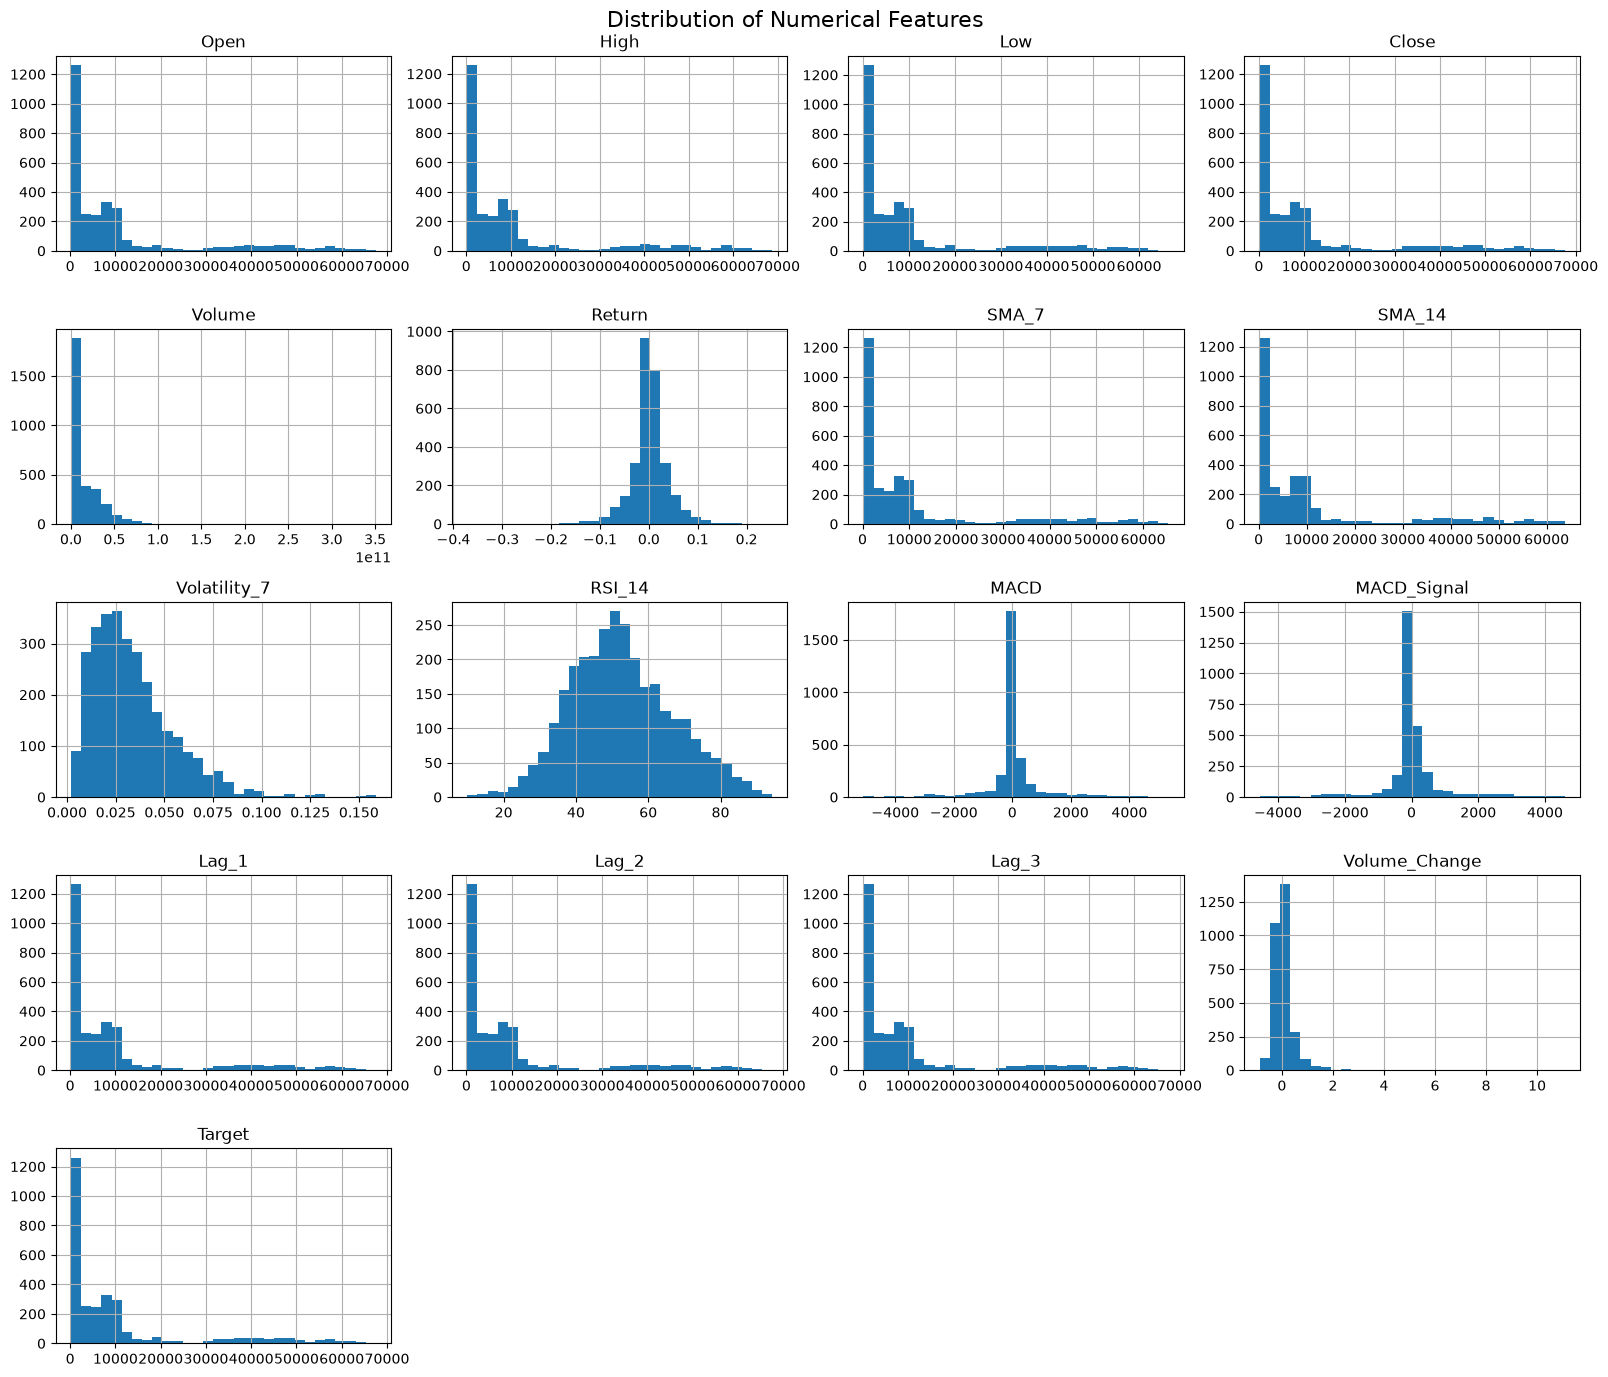

In [30]:
# Numerical feature distributions

numeric_features = [
    "Open", "High", "Low", "Close", "Volume",
    "Return", "SMA_7", "SMA_14", "Volatility_7",
    "RSI_14", "MACD", "MACD_Signal",
    "Lag_1", "Lag_2", "Lag_3",
    "Volume_Change", "Target"
]

df[numeric_features].hist(figsize=(16, 14), bins=30)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

## Bitcoin Price Trend Over Time

The historical Bitcoin closing price is visualized over time to identify long-term trends, major price movements and changes in the time series.

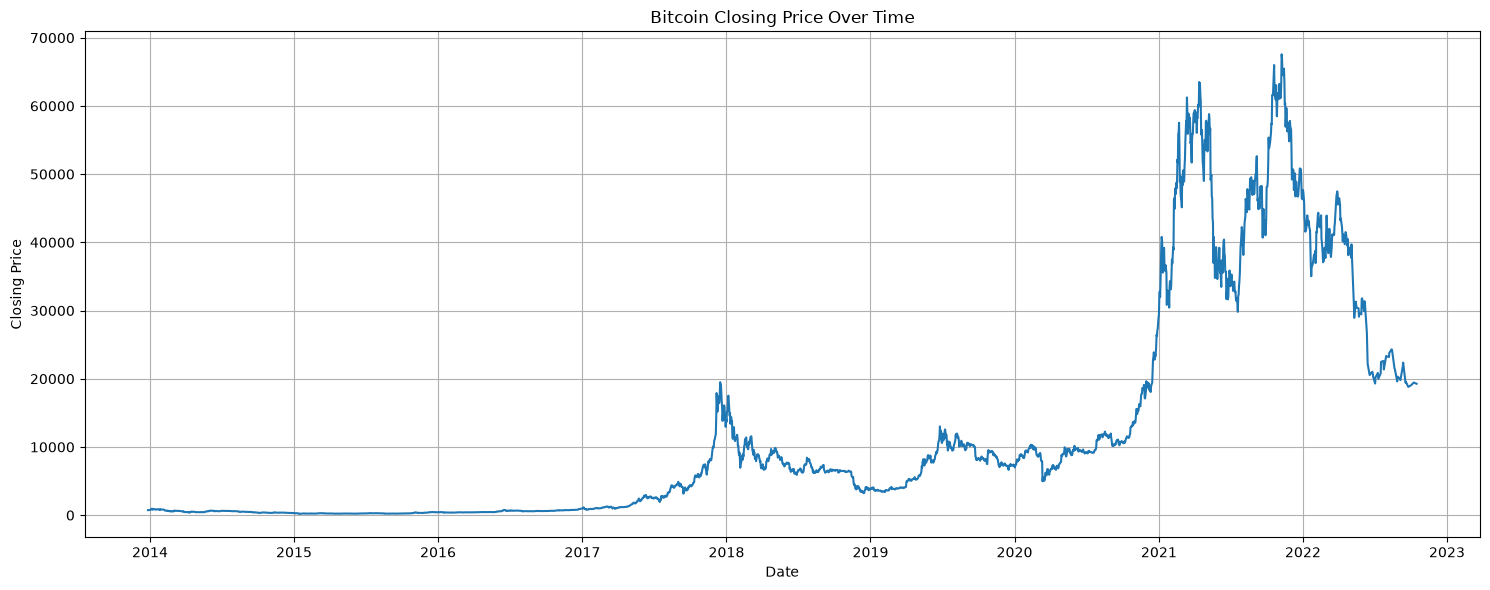

In [44]:
# Bitcoin closing price trend

plt.figure(figsize=(15, 6))

plt.plot(df["Date"], df["Close"])

plt.title("Bitcoin Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)

plt.tight_layout()
plt.savefig("../outputs/graphs/01_bitcoin_price_trend.png", dpi=300, bbox_inches="tight")
plt.show()

## Trading Volume Over Time

The historical trading volume is visualized to identify changes in market activity and periods of unusually high trading volume.

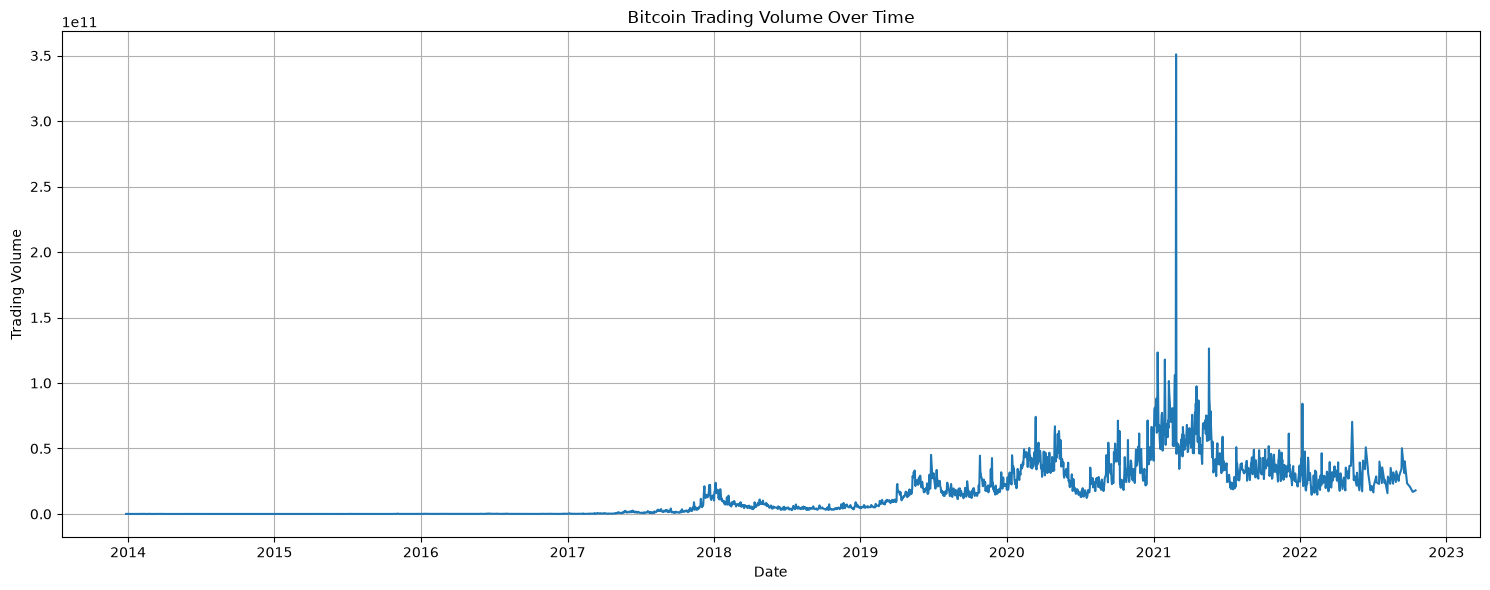

In [45]:
# Trading volume over time

plt.figure(figsize=(15, 6))

plt.plot(df["Date"], df["Volume"])

plt.title("Bitcoin Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.grid(True)

plt.tight_layout()
plt.savefig("../outputs/graphs/02_trading_volume.png", dpi=300, bbox_inches="tight")
plt.show()

## Daily Returns Over Time

The daily returns are visualized to examine short-term price movements, fluctuations and periods of high market volatility.

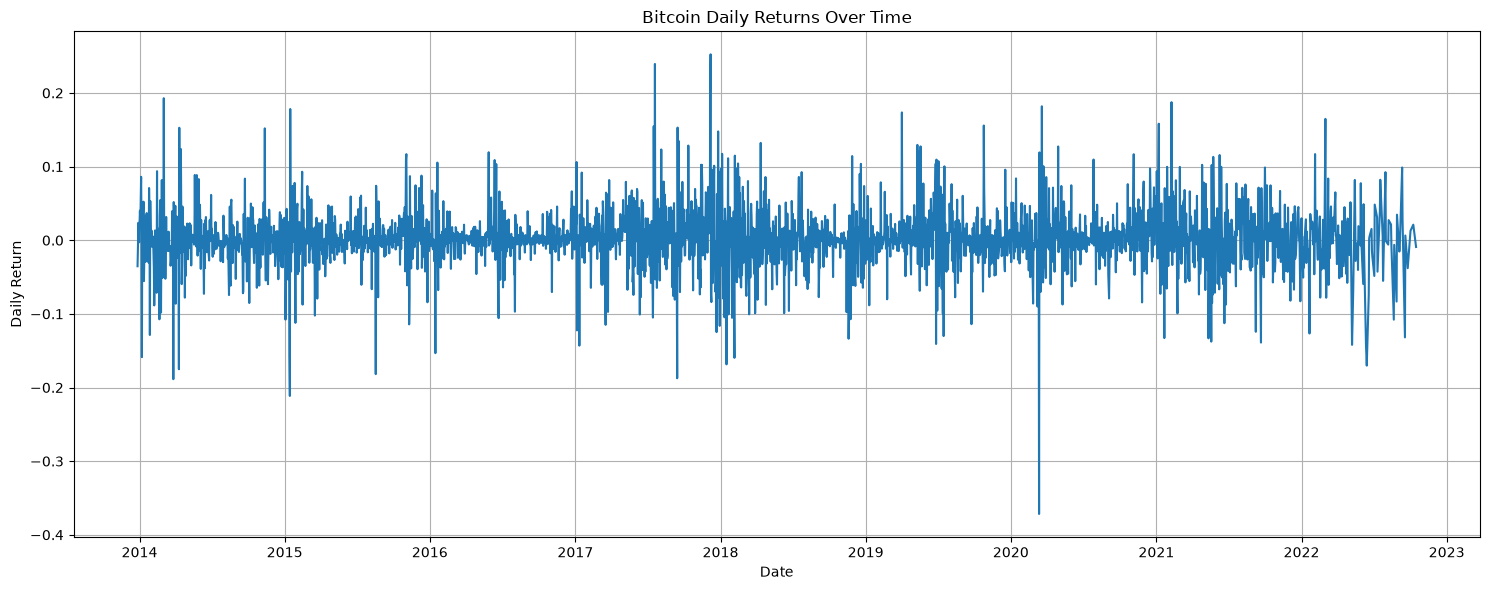

In [46]:
# Daily returns over time

plt.figure(figsize=(15, 6))

plt.plot(df["Date"], df["Return"])

plt.title("Bitcoin Daily Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.grid(True)

plt.tight_layout()
plt.savefig("../outputs/graphs/03_daily_returns.png", dpi=300, bbox_inches="tight")
plt.show()

## Rolling Volatility Over Time

The 7-day rolling volatility is visualized to identify periods of increased and decreased market uncertainty.

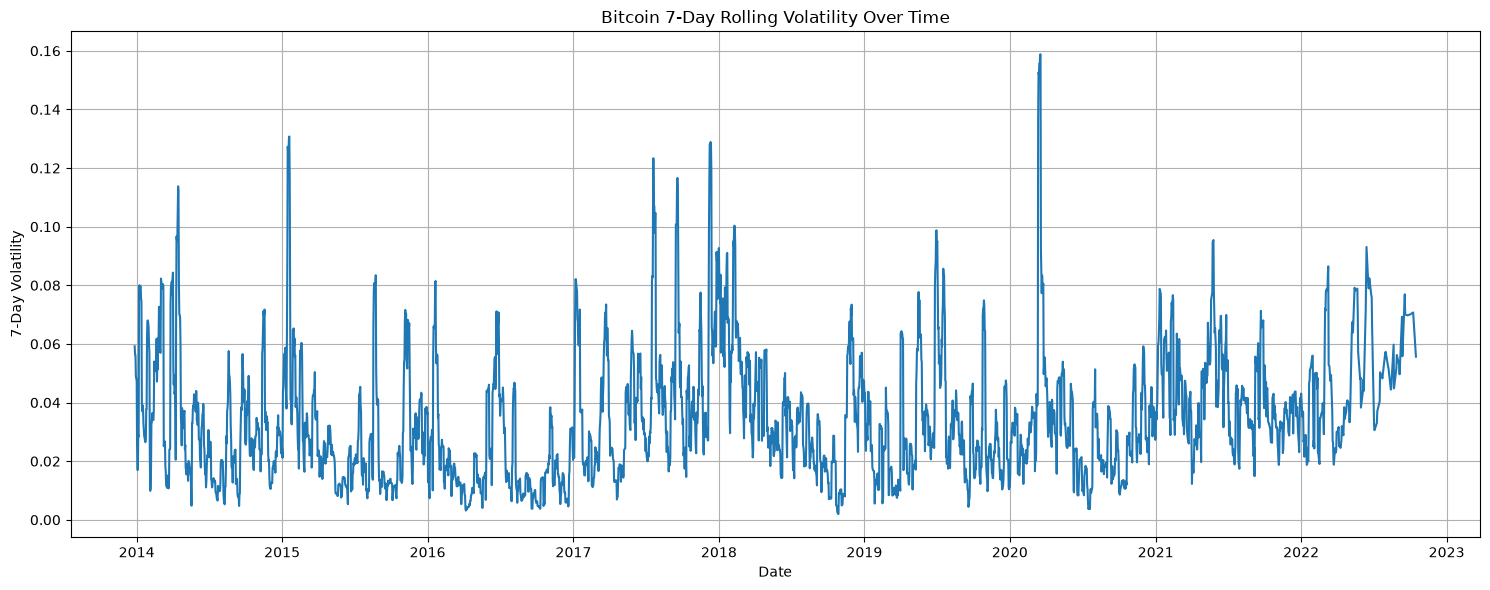

In [47]:
# Rolling volatility over time

plt.figure(figsize=(15, 6))

plt.plot(df["Date"], df["Volatility_7"])

plt.title("Bitcoin 7-Day Rolling Volatility Over Time")
plt.xlabel("Date")
plt.ylabel("7-Day Volatility")
plt.grid(True)

plt.tight_layout()
plt.savefig("../outputs/graphs/04_rolling_volatility.png", dpi=300, bbox_inches="tight")
plt.show()

## Correlation Analysis

The correlation between numerical variables is examined to understand relationships between features and identify highly correlated variables.

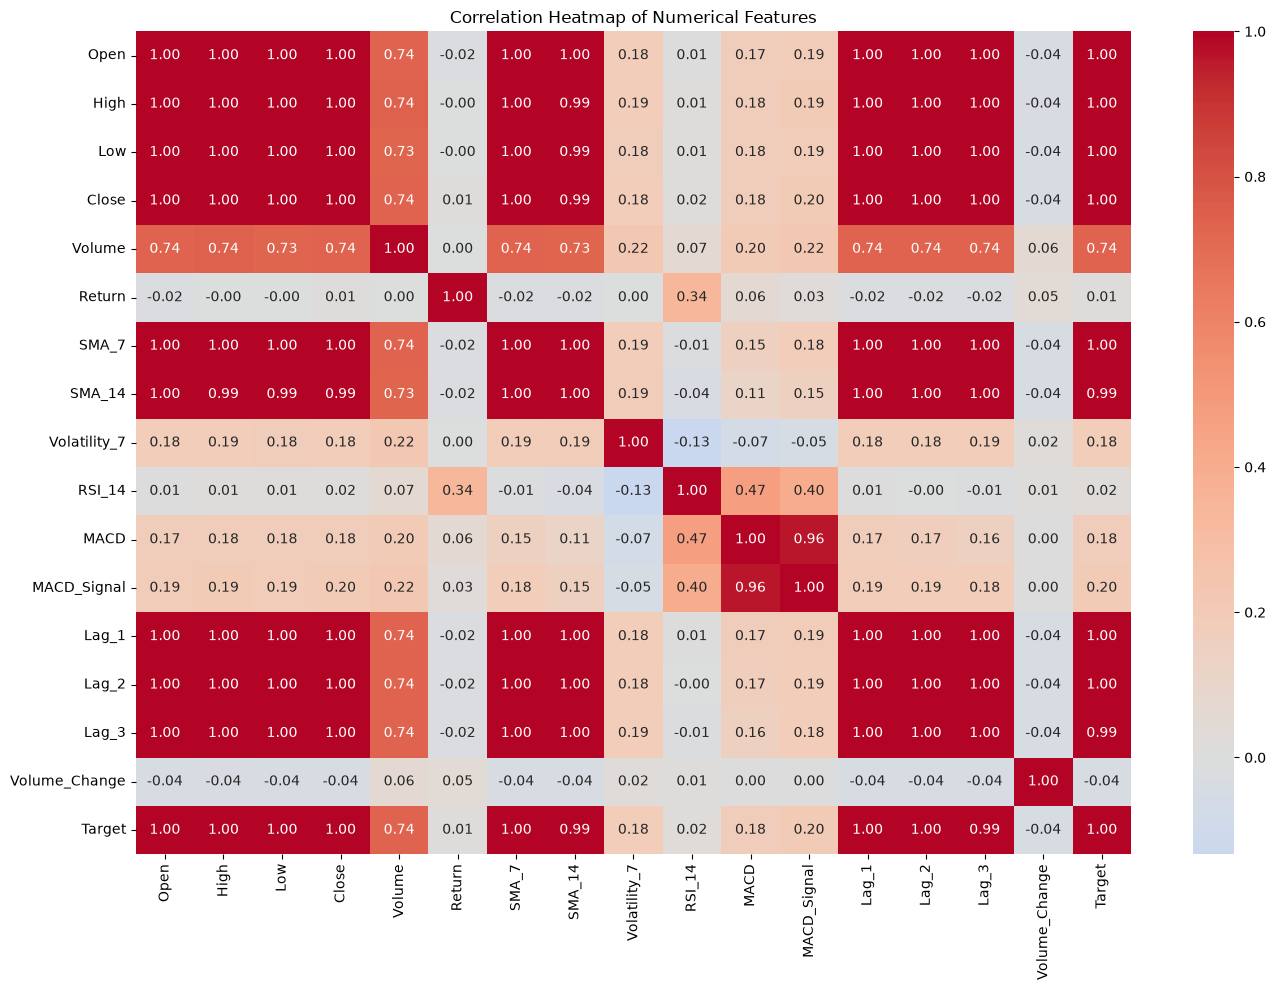

In [48]:
# Correlation analysis

correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.savefig("../outputs/graphs/05_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## Outlier Analysis

Outliers in the numerical variables are examined to identify extreme observations that may represent unusual market movements or abnormal trading activity.

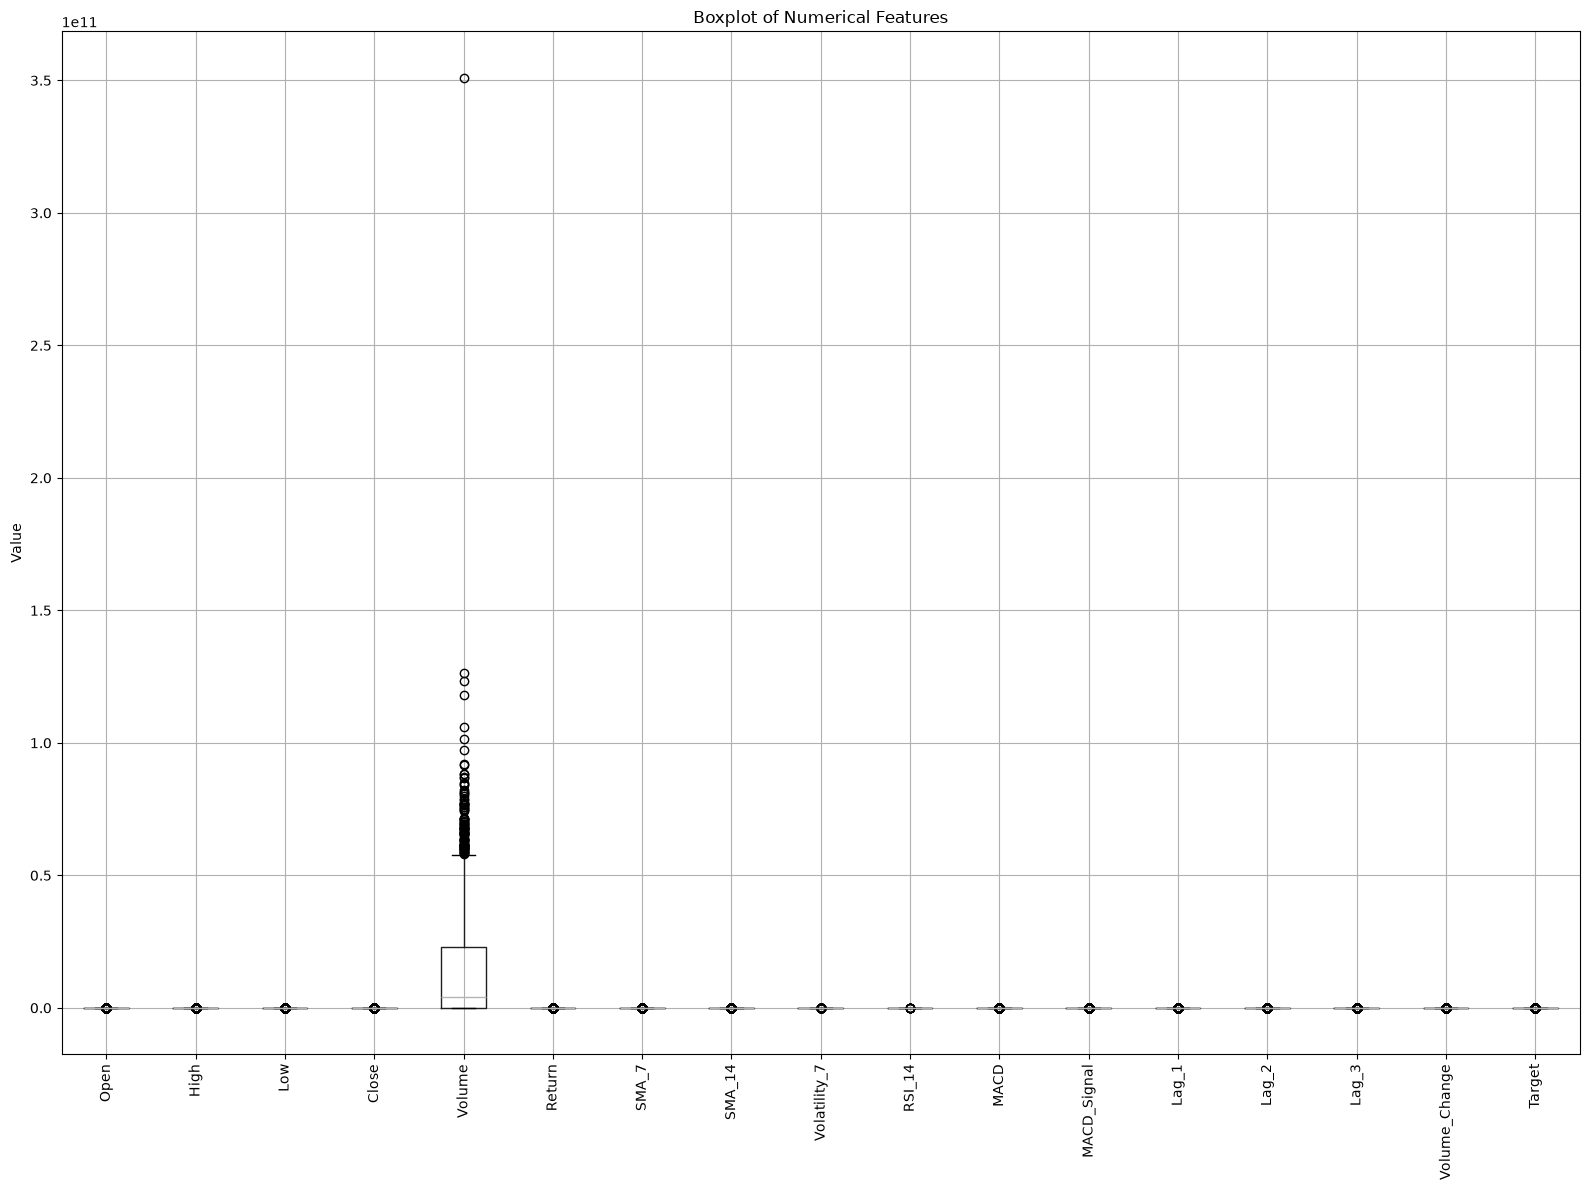

In [49]:
# Outlier analysis using boxplots

plt.figure(figsize=(16, 12))

df[numeric_features].boxplot(rot=90)

plt.title("Boxplot of Numerical Features")
plt.ylabel("Value")
plt.tight_layout()
plt.savefig("../outputs/graphs/06_outlier_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
# IQR outlier count

outlier_summary = []

for column in numeric_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    outlier_summary.append([column, outlier_count])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Feature", "Outlier Count"]
)

display(outlier_df)

,Feature,Outlier Count
0,Open,428
1,High,428
2,Low,429
3,Close,428
4,Volume,98
5,Return,294
6,SMA_7,429
7,SMA_14,432
8,Volatility_7,77
9,RSI_14,8


In [38]:
# Outlier percentage

outlier_df["Outlier Percentage"] = (
    outlier_df["Outlier Count"] / len(df) * 100
)

display(outlier_df)

,Feature,Outlier Count,Outlier Percentage
0,Open,428,14.214547
1,High,428,14.214547
2,Low,429,14.247758
3,Close,428,14.214547
4,Volume,98,3.254733
5,Return,294,9.764198
6,SMA_7,429,14.247758
7,SMA_14,432,14.347393
8,Volatility_7,77,2.557290
9,RSI_14,8,0.265692


## Feature Relationship with Target

The relationship between the numerical features and the target variable is examined to identify features that may provide useful information for cryptocurrency price forecasting.

In [39]:
# Correlation with target

target_correlation = df[numeric_features].corr()["Target"].sort_values(ascending=False)

print("Correlation of numerical features with Target:")
display(target_correlation.to_frame(name="Correlation"))

Correlation of numerical features with Target:


,Correlation
Target,1.000000
Close,0.998639
High,0.998244
Low,0.997993
Open,0.997651
Lag_1,0.997410
SMA_7,0.996125
Lag_2,0.996083
Lag_3,0.994727
SMA_14,0.992664


## Key Feature Relationships

Selected features are visualized against the target to examine their relationships and identify linear or nonlinear patterns.

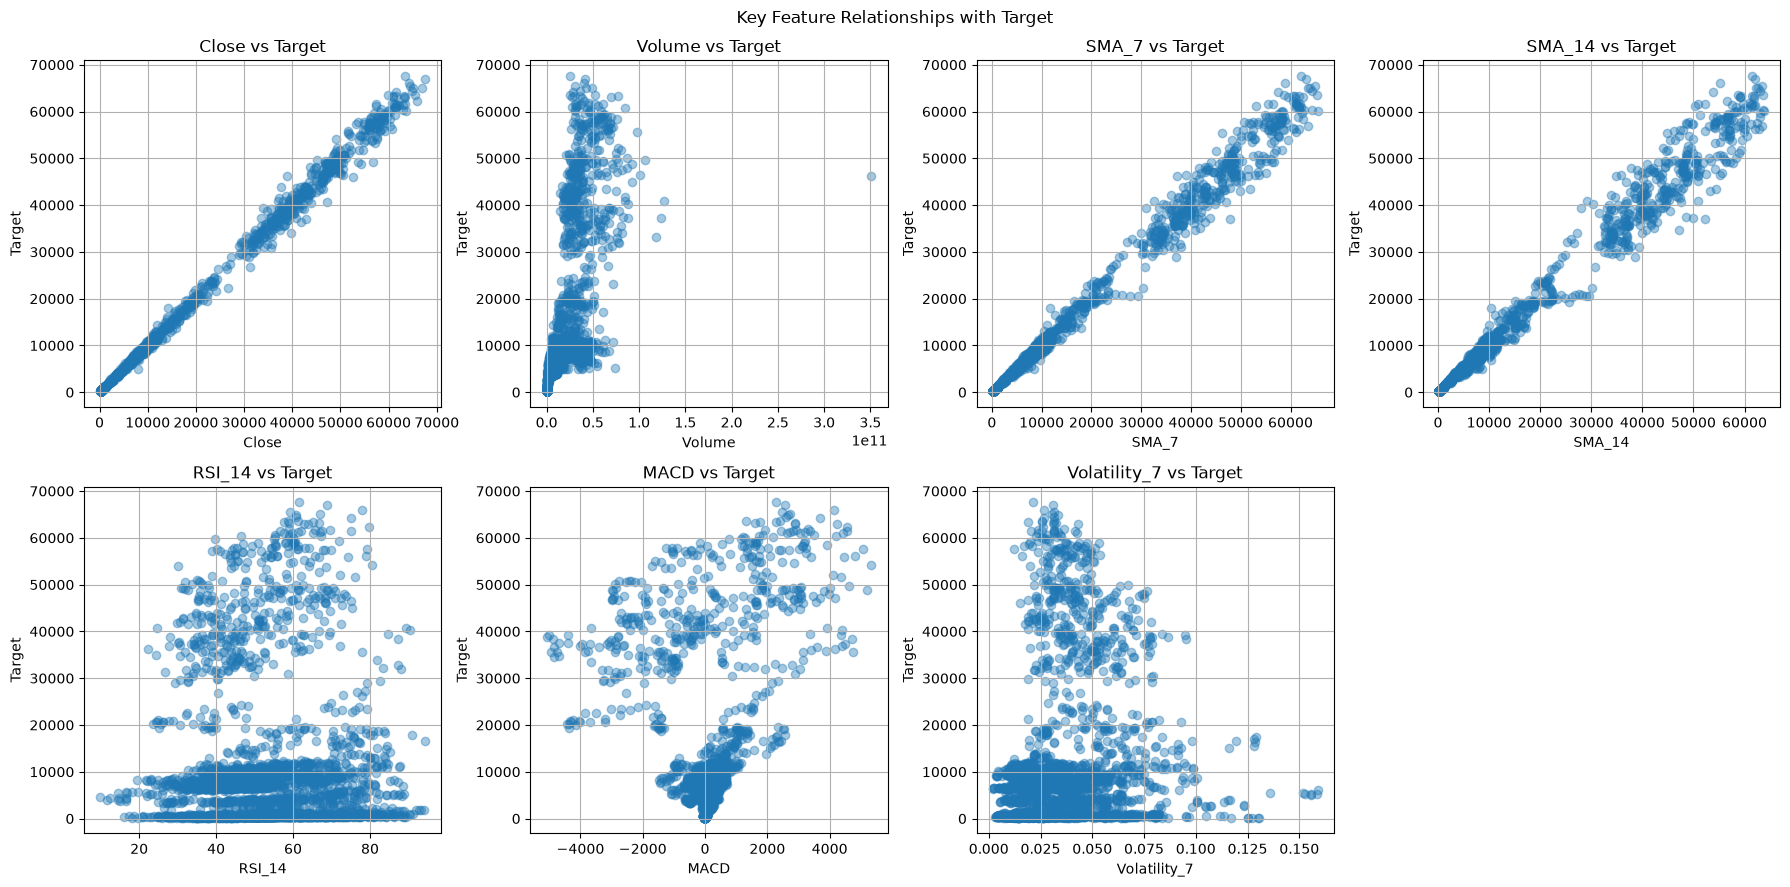

In [50]:
# Key feature relationships with target

key_features = [
    "Close",
    "Volume",
    "SMA_7",
    "SMA_14",
    "RSI_14",
    "MACD",
    "Volatility_7"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, feature in enumerate(key_features):
    axes[i].scatter(df[feature], df["Target"], alpha=0.4)
    axes[i].set_title(f"{feature} vs Target")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Target")
    axes[i].grid(True)

axes[-1].axis("off")

plt.suptitle("Key Feature Relationships with Target")
plt.tight_layout()
plt.savefig("../outputs/graphs/07_feature_target_relationships.png", dpi=300, bbox_inches="tight")
plt.show()

## Moving Average Analysis

The 7-day and 14-day moving averages are compared with the Bitcoin closing price to examine short-term and medium-term price trends.

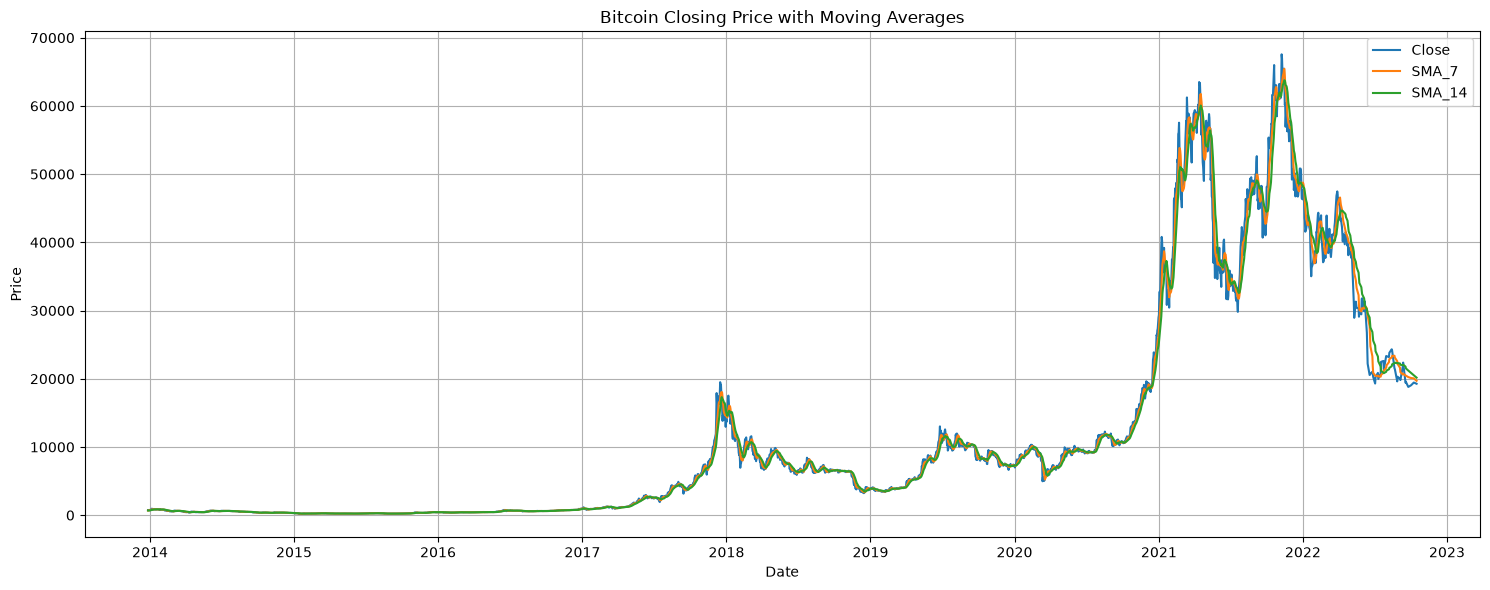

In [51]:
# Moving average analysis

plt.figure(figsize=(15, 6))

plt.plot(df["Date"], df["Close"], label="Close")
plt.plot(df["Date"], df["SMA_7"], label="SMA_7")
plt.plot(df["Date"], df["SMA_14"], label="SMA_14")

plt.title("Bitcoin Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("../outputs/graphs/08_moving_average_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## Technical Indicator Analysis

The RSI and MACD indicators are examined to understand momentum and trend-related behavior in the Bitcoin price data.

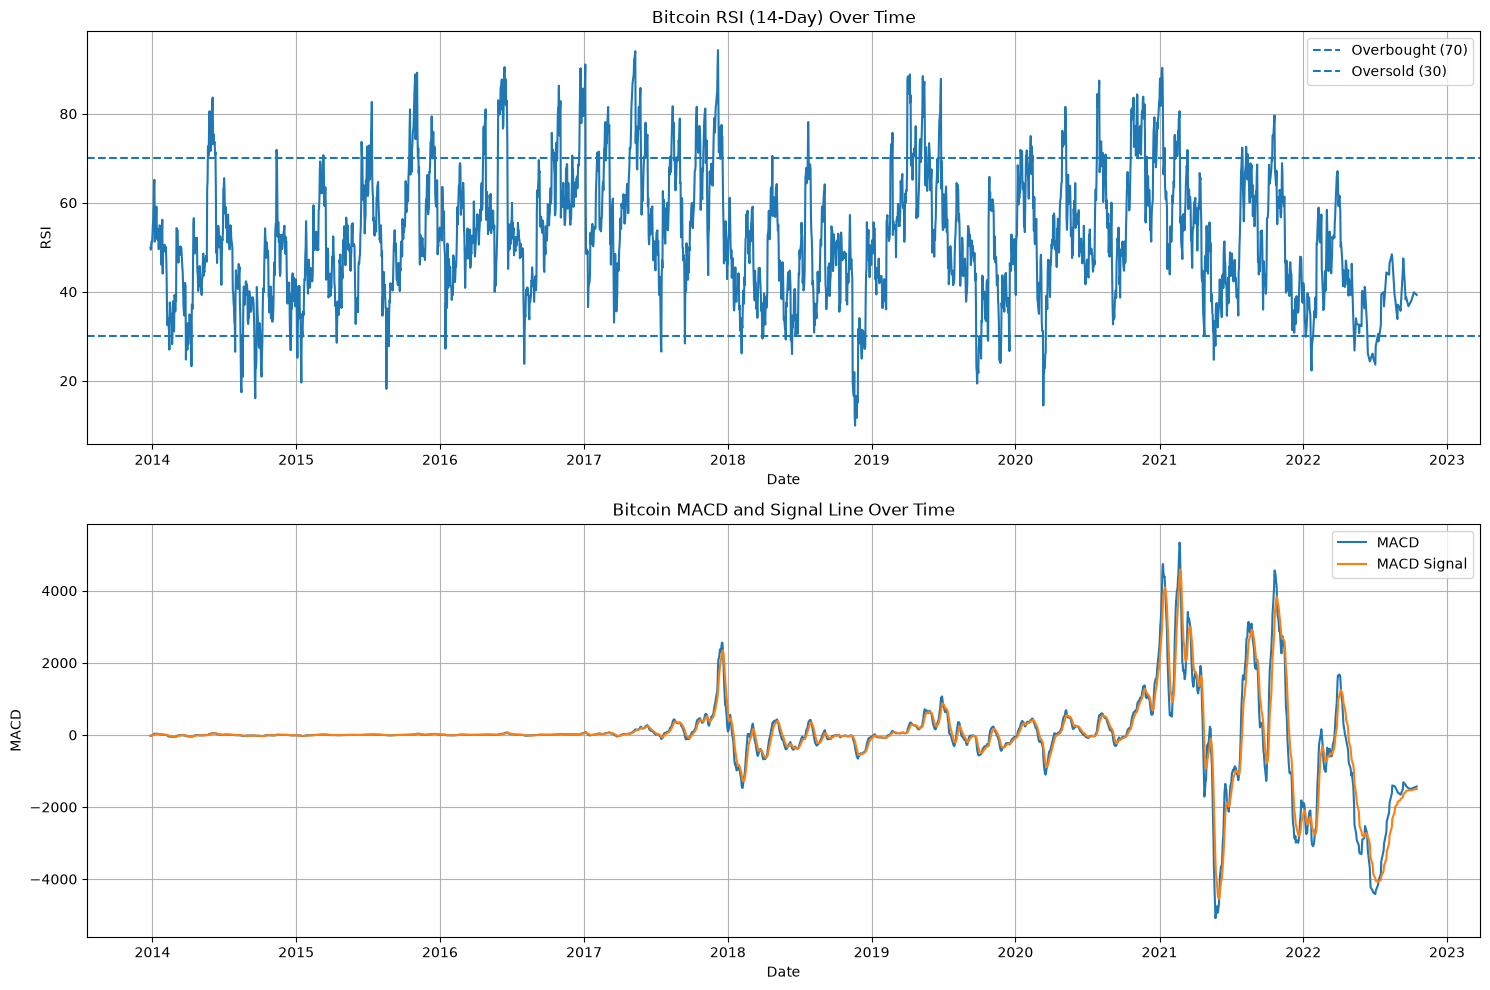

In [52]:
# Technical indicator analysis

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

axes[0].plot(df["Date"], df["RSI_14"])
axes[0].axhline(70, linestyle="--", label="Overbought (70)")
axes[0].axhline(30, linestyle="--", label="Oversold (30)")
axes[0].set_title("Bitcoin RSI (14-Day) Over Time")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("RSI")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(df["Date"], df["MACD"], label="MACD")
axes[1].plot(df["Date"], df["MACD_Signal"], label="MACD Signal")
axes[1].set_title("Bitcoin MACD and Signal Line Over Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("MACD")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("../outputs/graphs/09_technical_indicator_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## EDA Summary

The exploratory analysis provides the following key findings:

- The dataset contains historical Bitcoin OHLCV data along with engineered technical and lag-based features.
- The data is chronologically ordered and contains no duplicate dates or duplicate rows.
- Missing and infinite values were identified and appropriately handled before further analysis.
- Bitcoin prices and trading volume show substantial variation over time, with major increases during periods of strong market activity.
- Daily returns fluctuate around zero with occasional extreme movements, indicating periods of high short-term volatility.
- The 7-day rolling volatility highlights periods of increased market uncertainty.
- Several price-based and lag-based features show strong correlation with the target price, while indicators such as RSI, MACD and volatility capture additional market behavior.
- The distributions of several numerical variables are highly skewed, particularly price and volume-related variables.
- Outlier analysis identifies extreme observations that are consistent with major cryptocurrency market movements and should therefore be interpreted carefully rather than automatically removed.
- Moving averages capture short- and medium-term price trends, while RSI and MACD provide momentum and trend information.
- These findings provide a basis for preprocessing, feature selection and time-series modeling using Prophet and HistGradientBoosting.

In [43]:
# Final EDA verification

print("EDA completed successfully.")
print("Final dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total infinite values:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())
print("Total duplicate rows:", df.duplicated().sum())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

EDA completed successfully.
Final dataset shape: (3011, 18)
Total missing values: 0
Total infinite values: 0
Total duplicate rows: 0
Date range: 2013-12-27 00:00:00 to 2022-10-16 00:00:00
